# FaceLock — Google Colab walkthrough

This notebook runs the copied FaceLock project in Google Colab. It includes single-image editing, single-image protection, and batch commands. Use a Colab GPU runtime for practical performance; the defense scripts require CUDA.

## Before you start

1. Upload this notebook (`FaceLock_Colab/FaceLock_Colab.ipynb`) to Google Drive and open it with Google Colab.
2. In Colab, select **Runtime → Change runtime type → T4 GPU** (or another GPU), then save.
3. Make a ZIP of the complete `FaceLock_Colab` folder on your computer. The next cells will ask you to upload it. Keep the `.py` files and `evaluation/` folder together.
4. Run the cells from top to bottom. Model weights download from Hugging Face the first time and require internet access.

Colab GPU availability varies by account and session. If the GPU check below reports no CUDA, change the runtime type and reconnect before running the defense workflow. Editing can fall back to CPU, but diffusion on CPU is very slow.


## 1. Check the runtime

In [12]:
import torch
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. In Colab choose Runtime > Change runtime type > T4 GPU, then reconnect.")


PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


## 2. Install project dependencies

This installs the project libraries while leaving Colab’s preinstalled CUDA-enabled PyTorch in place.

In [13]:
%pip install -q --upgrade --only-binary=tokenizers,safetensors,sentencepiece "diffusers==0.31.0" "transformers<5" accelerate "huggingface_hub>=0.34.0,<1.0" safetensors sentencepiece lpips kornia scikit-image timm pillow-avif-plugin matplotlib


In [14]:
%pip uninstall -y opencv-python opencv-contrib-python opencv-python-headless opencv-contrib-python-headless
%pip install -q --no-cache-dir "opencv-python-headless<5"


Found existing installation: opencv-python-headless 4.14.0.94
Uninstalling opencv-python-headless-4.14.0.94:
  Successfully uninstalled opencv-python-headless-4.14.0.94


In [15]:
import cv2
print("OpenCV:", cv2.__version__, cv2.__file__)
assert hasattr(cv2, "CascadeClassifier"), "OpenCV install is incomplete; restart runtime and rerun the OpenCV install cell."


OpenCV: 4.14.0 /usr/local/lib/python3.13/dist-packages/cv2/__init__.py


In [16]:
from importlib.metadata import version, PackageNotFoundError
for package in ["diffusers", "transformers", "accelerate", "huggingface-hub", "safetensors", "sentencepiece", "lpips", "kornia", "scikit-image", "timm", "opencv-python-headless", "pillow-avif-plugin", "matplotlib"]:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: not installed")
import torch
print("PyTorch (kept from Colab runtime):", torch.__version__, "CUDA:", torch.version.cuda)


diffusers: 0.31.0
transformers: 4.57.6
accelerate: 1.15.0
huggingface-hub: 0.36.2
safetensors: 0.8.0
sentencepiece: 0.2.2
lpips: 0.1.4
kornia: 0.9.0
scikit-image: 0.26.0
timm: 1.0.30
opencv-python-headless: 4.14.0.94
pillow-avif-plugin: 1.6.0
matplotlib: 3.11.2
PyTorch (kept from Colab runtime): 2.11.0+cu130 CUDA: 13.0


## 3. Upload and unpack the project ZIP

Create the ZIP on your computer by right-clicking the `FaceLock_Colab` folder and choosing **Compress/Send to ZIP**. Upload that ZIP when prompted. The cell locates `edit.py` even if your ZIP contains an extra top-level folder.

In [17]:
from google.colab import files
from pathlib import Path
import zipfile
import shutil

uploaded = files.upload()  # Choose the FaceLock_Colab.zip file
zip_name = next((name for name in uploaded if name.lower().endswith(".zip")), None)
if zip_name is None:
    raise ValueError("Please upload the ZIP archive of the FaceLock_Colab project folder.")

work_dir = Path("/content/FaceLock_Colab")
if work_dir.exists():
    shutil.rmtree(work_dir)
work_dir.mkdir(parents=True)
with zipfile.ZipFile(zip_name) as archive:
    archive.extractall(work_dir)
edit_script = next(work_dir.rglob("edit.py"), None)
if edit_script is None:
    raise FileNotFoundError("edit.py was not found in the ZIP. Zip the complete FaceLock_Colab folder.")
PROJECT_DIR = edit_script.parent
print("Project folder:", PROJECT_DIR)
print("Project files:", len(list(PROJECT_DIR.iterdir())))


Saving FaceLock_Colab.zip to FaceLock_Colab (1).zip
Project folder: /content/FaceLock_Colab/FaceLock_Colab
Project files: 22


## 4. Edit one image

The ZIP already contains sample images. You can use one, or upload your own image in the next cell. The prompt below is an example; change it to your desired edit.

In [18]:
from pathlib import Path
from google.colab import files

# Keep True to use the included sample image. Set False to upload your own image.
USE_SAMPLE_IMAGE = True
if USE_SAMPLE_IMAGE:
    INPUT_IMAGE = PROJECT_DIR / "portrait-white-man-isolated.jpg"
else:
    uploaded_image = files.upload()  # Select one JPG, PNG, WEBP, or AVIF image
    INPUT_IMAGE = Path(next(iter(uploaded_image)))
print("Input image:", INPUT_IMAGE)


Input image: /content/FaceLock_Colab/FaceLock_Colab/portrait-white-man-isolated.jpg


In [8]:
from pathlib import Path

edit_script = PROJECT_DIR / "edit.py"
source = edit_script.read_text()

start = source.index('    if device == "cuda":')
end = source.index("    # 3. edit the image", start)

correct_block = '''    if device == "cuda":
        model.enable_model_cpu_offload()
        model.enable_attention_slicing("max")
    else:
        model.to(device)

'''

edit_script.write_text(source[:start] + correct_block + source[end:])
print("Fixed indentation in", edit_script)

ValueError: substring not found

I0000 00:00:1793550261.276075    7340 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793550266.431738    7340 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]`torch_dtype` is deprecated! Use `dtype` instead!

Loading pipeline components...: 100%|██████████| 6/6 [00:10<00:00,  1.71s/it]
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py:2589: UserWarning: for net.pos_e

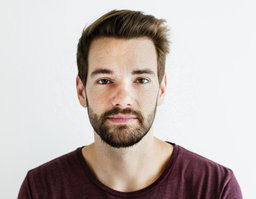

In [20]:

import gc
import subprocess
import torch
from pathlib import Path
from PIL import Image
from IPython.display import display

PROTECT_INPUT = Path("/content/facelock_protect_256.png")
with Image.open(INPUT_IMAGE) as image:
    image = image.convert("RGB")
    image.thumbnail((256, 256), Image.Resampling.LANCZOS)
    image.save(PROTECT_INPUT)

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

PROTECTED_IMAGE = Path("/content/protected_result.png")
command = [
    "python", str(PROJECT_DIR / "defend.py"),
    "--input_path", str(PROTECT_INPUT),
    "--output_path", str(PROTECTED_IMAGE),
    "--defend_method", "multiface",
    "--attack_budget", "0.03",
    "--step_size", "0.01",
    "--num_iters", "5",
    "--warm_start_iters", "1",
]

result = subprocess.run(
    command,
    cwd=PROJECT_DIR,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
)
print(result.stdout)

if result.returncode:
    raise RuntimeError(f"Protection failed with exit code {result.returncode}")
if not PROTECTED_IMAGE.exists():
    raise FileNotFoundError(f"Protection did not create {PROTECTED_IMAGE}")

display(Image.open(PROTECTED_IMAGE))


## 5. Protect one image (FaceLock)

The protection scripts download identity/alignment checkpoints from Hugging Face. Create a **read** access token at Hugging Face and make sure you have access to the required model repositories. Paste the token when prompted; it is kept in this Colab runtime only. For a quick first run, the example uses fewer optimization iterations. Increase `num_iters` and `warm_start_iters` for a longer run.

In [19]:
import os
from getpass import getpass

os.environ["HF_HOME"] = "/content/huggingface_cache"
os.environ["HUGGINGFACE_HUB_TOKEN"] = getpass("Hugging Face read token: ")


Hugging Face read token: ··········


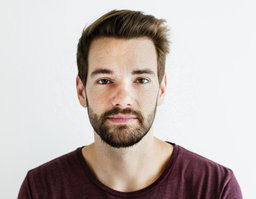

In [21]:
# FaceLock keeps several models and gradient activations on the GPU.
# Resize large photos before protection to fit a Colab T4 (the result is also 384px max).
PROTECT_INPUT = Path("/content/facelock_protect_384.png")
with Image.open(INPUT_IMAGE) as image:
    image = image.convert("RGB")
    image.thumbnail((384, 384), Image.Resampling.LANCZOS)
    image.save(PROTECT_INPUT)

PROTECTED_IMAGE = Path("/content/protected_result.png")
command = [
    "python", str(PROJECT_DIR / "defend.py"),
    "--input_path", str(PROTECT_INPUT),
    "--output_path", str(PROTECTED_IMAGE),
    "--defend_method", "multiface",
    "--attack_budget", "0.03",
    "--step_size", "0.01",
    "--num_iters", "30",
    "--warm_start_iters", "5",
]
import subprocess

def run_project_command(command, cwd=PROJECT_DIR):
    result = subprocess.run(
        command,
        cwd=cwd,
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
    )
    print(result.stdout)

    if result.returncode != 0:
        raise RuntimeError(
            f"Command failed with exit code {result.returncode}; see output above."
        )

if not PROTECTED_IMAGE.exists():
    raise FileNotFoundError(f"Protection did not create {PROTECTED_IMAGE}")
display(Image.open(PROTECTED_IMAGE))


## 6. Edit the protected image (optional)

This applies the same editing prompt to the protected image, so you can inspect the result.

Enter an editing prompt: Make this man a spiderman
I0000 00:00:1793550355.250193    7784 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.

Loading pipeline components...:  50%|█████     | 3/6 [00:08<00:11,  3.89s/it]`torch_dtype` is deprecated! Use `dtype` instead!

Loading pipeline components...: 100%|██████████| 6/6 [00:09<00:00,  1.59s/it]

100%|██████████| 30/30 [00:02<00:00, 13.98it/s]



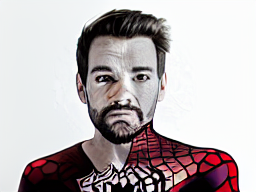

In [22]:
PROMPT = input("Enter an editing prompt: ").strip()
if not PROMPT:
    raise ValueError("Please enter an editing prompt.")

PROTECTED_EDIT = Path("/content/protected_edited.png")
command = [
    "python", str(PROJECT_DIR / "edit.py"),
    "--input_path", str(PROTECTED_IMAGE),
    "--prompt", PROMPT,
    "--num_inference_steps", "30",
    "--image_guidance_scale", "1.5",
    "--guidance_scale", "7.5",
    "--output_path", str(PROTECTED_EDIT),
]
run_project_command(command)
display(Image.open(PROTECTED_EDIT))


## 7. Batch workflows (optional)

Upload a ZIP containing a folder of input images, unpack it, then point the project batch scripts at those directories. Example command from a notebook cell:

```python
subprocess.run([
    "python", str(PROJECT_DIR / "main_edit.py"),
    "--src_dir", "/content/portraits",
    "--edit_dir", "/content/edits",
    "--num_inference_steps", "30",
], cwd=PROJECT_DIR, check=True)
```

For batch protection, use `main_defend.py` with `--image_dir`, `--output_dir`, and `--defend_method multiface`. The same Hugging Face token and a GPU runtime are required. See `README.md` and `MULTIFACE_ARCHITECTURE.md` in the copied folder for all command options, evaluation scripts, and method details.

### View the calculated metrics in the notebook

The calculations are performed by `evaluation/eval_multiface.py`; this cell loads and displays its output CSV tables below.


In [23]:
import pandas as pd
for name in ["per_face_privacy.csv", "image_quality.csv", "robustness.csv", "editing_robustness.csv", "reidentification.csv", "efficiency.csv"]:
    path = RESULTS_DIR / name
    if path.exists():
        print("\n", name)
        display(pd.read_csv(path))
    else:
        print(f"{name}: not produced (optional inputs may be missing)")


NameError: name 'RESULTS_DIR' is not defined

## Standalone evaluation cell

Run this after you have matching clean and protected image folders. It prompts for their paths, calculates the available metrics, writes CSVs, and displays them. `PROJECT_DIR` must already point to the uploaded FaceLock project, and the Hugging Face token from section 5 must still be set.


In [24]:
from pathlib import Path
import os, subprocess, sys
import pandas as pd

CLEAN_DIR = Path(input("Path to clean images folder: ").strip()).expanduser()
PROTECTED_DIR = Path(input("Path to matching protected images folder: ").strip()).expanduser()
RESULTS_DIR = Path(input("Where to save metrics [default /content/facelock_metrics]: ").strip() or "/content/facelock_metrics")
THRESHOLD = input("Calibrated verification threshold (-1 to 1) [example only 0.35]: ").strip() or "0.35"

for label, folder in (("clean", CLEAN_DIR), ("protected", PROTECTED_DIR)):
    if not folder.is_dir():
        raise FileNotFoundError(f"{label} image folder not found: {folder}")
if "HF_HOME" not in os.environ:
    os.environ["HF_HOME"] = "/content/huggingface_cache"
if "HUGGINGFACE_HUB_TOKEN" not in os.environ:
    from getpass import getpass
    os.environ["HUGGINGFACE_HUB_TOKEN"] = getpass("Hugging Face read token: ")

cmd = [sys.executable, str(PROJECT_DIR / "evaluation/eval_multiface.py"),
       "--clean_dir", str(CLEAN_DIR), "--protected_dir", str(PROTECTED_DIR),
       "--output_dir", str(RESULTS_DIR), "--verification_threshold", THRESHOLD]
runtime_csv = PROTECTED_DIR / "efficiency.csv"
if runtime_csv.exists(): cmd += ["--runtime_csv", str(runtime_csv)]
clean_edits = CLEAN_DIR.parent / "clean_edits"
protected_edits = CLEAN_DIR.parent / "protected_edits"
if clean_edits.is_dir() and protected_edits.is_dir():
    cmd += ["--clean_edits_dir", str(clean_edits), "--protected_edits_dir", str(protected_edits)]
r = subprocess.run(cmd, cwd=PROJECT_DIR, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
print(r.stdout)
if r.returncode:
    raise RuntimeError(f"Evaluation failed with exit code {r.returncode}")

for name in ["per_face_privacy.csv", "image_quality.csv", "robustness.csv", "editing_robustness.csv", "reidentification.csv", "efficiency.csv"]:
    path = RESULTS_DIR / name
    if path.exists():
        print("\n" + name)
        display(pd.read_csv(path))
print("\nMetric CSVs saved in:", RESULTS_DIR)


Path to clean images folder: /content
Path to matching protected images folder: /content
Where to save metrics [default /content/facelock_metrics]: /content
Calibrated verification threshold (-1 to 1) [example only 0.35]: 0.35
I0000 00:00:1793550452.289738    8232 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793550455.376198    8232 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py:2589

,box_xyxy,cosine_similarity,face_index,filename,similarity_drop,threshold,verification_attack_success
0,"38,1,209,182",1.0,0,facelock_protect_256.png,5.960464e-08,0.35,0
1,"56,0,314,274",1.0,0,facelock_protect_384.png,0.000000e+00,0.35,0
2,"40,1,203,176",1.0,0,protected_edited.png,5.960464e-08,0.35,0
3,"38,1,209,182",1.0,0,protected_result.png,0.000000e+00,0.35,0



image_quality.csv


,clip_image_similarity,faces,filename,lpips,psnr_db,ssim
0,1.0,1,facelock_protect_256.png,0.0,inf,1.0
1,1.0,1,facelock_protect_384.png,0.0,inf,1.0
2,1.0,1,protected_edited.png,0.0,inf,1.0
3,1.0,1,protected_result.png,0.0,inf,1.0



robustness.csv


,attack_success_rate,cosine_similarity_drop_vs_clean,faces,filename,transform,worst_face_similarity
0,0.0,0.000000e+00,1,facelock_protect_256.png,resize,1.0
1,0.0,0.000000e+00,1,facelock_protect_256.png,crop,1.0
2,0.0,1.192093e-07,1,facelock_protect_256.png,jpeg,1.0
3,0.0,0.000000e+00,1,facelock_protect_256.png,blur,1.0
4,0.0,-1.192093e-07,1,facelock_protect_384.png,resize,1.0
5,0.0,0.000000e+00,1,facelock_protect_384.png,crop,1.0
6,0.0,5.960464e-08,1,facelock_protect_384.png,jpeg,1.0
7,0.0,0.000000e+00,1,facelock_protect_384.png,blur,1.0
8,0.0,5.960464e-08,1,protected_edited.png,resize,1.0
9,0.0,5.960464e-08,1,protected_edited.png,crop,1.0



Metric CSVs saved in: /content


# Dataset benchmark: baseline FaceLock vs multi-person FaceLock

This section stages a **small user-provided sample**; it does not download or redistribute the full datasets. Create a ZIP with subfolders named for the source datasets and put a few permitted images in each (for example `CelebA/`, `LFW/`, `WIDER_FACE/`, `COCO/`). The cell caps each dataset at three images by default. Large datasets still require obtaining the archive separately; capping after upload limits computation, not transfer size. Respect dataset terms. FFHQ is excluded from face-recognition metrics because its source says it is not intended for developing/improving facial-recognition technology.

The comparison is an experiment, not a prediction: `facelock` is the repository baseline, `multiface` is the multi-person implementation. The hypothesis is that `multiface` lowers worst-face identity similarity on group photos, with higher runtime/memory; quality may trade off. The cells below report measured results for the uploaded sample.


## A. Upload and stage small dataset samples

In [25]:
from google.colab import files
from pathlib import Path
from PIL import Image
import zipfile, shutil, random

sample_upload = files.upload()  # ZIP with dataset-named subfolders
zip_name = next((f for f in sample_upload if f.lower().endswith(".zip")), None)
if not zip_name: raise ValueError("Upload a ZIP containing dataset-named image folders")
extract_root = Path("/content/facelock_dataset_upload")
BENCH_ROOT = Path("/content/facelock_benchmark")
if extract_root.exists(): shutil.rmtree(extract_root)
if BENCH_ROOT.exists(): shutil.rmtree(BENCH_ROOT)
extract_root.mkdir(parents=True); BENCH_ROOT.mkdir(parents=True)
with zipfile.ZipFile(zip_name) as z: z.extractall(extract_root)
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".avif"}
MAX_PER_DATASET = 75
random.seed(42)
DATASETS = {}
all_images = [p for p in extract_root.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
source_names = sorted({p.relative_to(extract_root).parts[0] if len(p.relative_to(extract_root).parts)>1 else "uploaded_images" for p in all_images})
for dataset in source_names:
    group = [p for p in all_images if (p.relative_to(extract_root).parts[0] if len(p.relative_to(extract_root).parts)>1 else "uploaded_images") == dataset]
    group = sorted(group)[:MAX_PER_DATASET]
    clean = BENCH_ROOT / dataset / "clean"
    clean.mkdir(parents=True, exist_ok=True)
    for idx, src in enumerate(group):
        # Unique stable filenames keep clean/protected/evaluation pairs aligned.
        dst = clean / f"{dataset}_{idx:03d}.png"
        with Image.open(src) as im:
            im = im.convert("RGB"); im.thumbnail((384,384), Image.Resampling.LANCZOS); im.save(dst)
    DATASETS[dataset] = clean
print({name: len(list(folder.glob("*.png"))) for name,folder in DATASETS.items()})


Saving photo.zip to photo.zip
{'photo': 1}


In [26]:

from PIL import Image
from pathlib import Path

for dataset, image_dir in DATASETS.items():
    image_dir = Path(image_dir)
    for path in image_dir.iterdir():
        if path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".webp", ".bmp"}:
            continue

        with Image.open(path) as image:
            image = image.convert("RGB")
            width, height = image.size
            new_size = (max(64, width // 8 * 8), max(64, height // 8 * 8))

            if new_size != image.size:
                image.resize(new_size, Image.Resampling.LANCZOS).save(path)

print("Resized staged images to dimensions divisible by 8.")


Resized staged images to dimensions divisible by 8.


In [27]:
import shutil
from pathlib import Path
from PIL import Image
import sys

sys.path.insert(0, str(PROJECT_DIR))
from methods import detect_face_boxes
from utils import pil_to_input

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".avif"}
FILTERED_ROOT = Path("/content/facelock_face_detected")
FILTERED_ROOT.mkdir(parents=True, exist_ok=True)

FILTERED_DATASETS = {}
SKIPPED_FACE_IMAGES = {}

for dataset, source_dir in DATASETS.items():
    source_dir = Path(source_dir)
    checked_dir = FILTERED_ROOT / dataset
    checked_dir.mkdir(parents=True, exist_ok=True)

    kept = []
    skipped = []

    for path in sorted(source_dir.iterdir()):
        if path.suffix.lower() not in IMAGE_EXTS:
            continue

        try:
            with Image.open(path) as image:
                image = image.convert("RGB")
                detect_face_boxes(pil_to_input(image))
                output_path = checked_dir / f"{path.stem}.png"
                image.save(output_path)
                kept.append(path.name)
        except RuntimeError as error:
            skipped.append((path.name, str(error)))

    if not kept:
        raise RuntimeError(f"No detectable faces in dataset {dataset}")

    FILTERED_DATASETS[dataset] = checked_dir
    SKIPPED_FACE_IMAGES[dataset] = skipped
    print(f"{dataset}: kept {len(kept)}, skipped {len(skipped)}")

DATASETS = FILTERED_DATASETS

for dataset, skipped in SKIPPED_FACE_IMAGES.items():
    if skipped:
        print(f"\nSkipped images in {dataset}:")
        for filename, reason in skipped:
            print(f"  {filename}: {reason}")

photo: kept 1, skipped 0


## B. Protect samples with `main_defend.py` (separate baseline and multi-face runs)

In [28]:
import subprocess, time, csv, os
from pathlib import Path

METHODS = ["facelock", "multiface"]
BUDGET = "0.03"
PROTECTED = {}
for dataset, clean_dir in DATASETS.items():
    for method in METHODS:
        out_root = BENCH_ROOT / dataset / method
        cmd = ["python", str(PROJECT_DIR/"main_defend.py"), "--image_dir", str(clean_dir),
               "--output_dir", str(out_root), "--defend_method", method,
               "--attack_budget", BUDGET, "--step_size", "0.01",
               "--num_iters", "5", "--warm_start_iters", "1"]
        if not os.environ.get("HUGGINGFACE_HUB_TOKEN"):
            raise RuntimeError("Set HUGGINGFACE_HUB_TOKEN before running FaceLock methods")
        start=time.perf_counter()
        r=subprocess.run(cmd,cwd=PROJECT_DIR,text=True,stdout=subprocess.PIPE,stderr=subprocess.STDOUT)
        print(f"{dataset}/{method}\n",r.stdout)
        if r.returncode: raise RuntimeError(f"main_defend.py failed for {dataset}/{method}")
        result_dir=out_root/f"budget_{BUDGET}"
        PROTECTED[(dataset,method)]=result_dir
        # Record comparable wall-clock time for both implementations.
        with open(result_dir/"benchmark_runtime.csv","w",newline="") as f:
            w=csv.DictWriter(f,fieldnames=["filename","runtime_seconds","steps","peak_gpu_memory_mb","face_count"]); w.writeheader()
            w.writerow({"filename":"__batch_total__","runtime_seconds":time.perf_counter()-start,"steps":"","peak_gpu_memory_mb":"","face_count":""})
print("Protection complete:", PROTECTED)


photo/facelock
I0000 00:00:1793550551.485675    8710 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793550554.038847    8710 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py:2589: UserWarning: for net.pos_embed: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state d

## C. Create matched edits with `main_edit.py` (separate cell)

The prompt is entered by you and the same seed/prompt/settings are used for clean, baseline-protected, and multi-face-protected images.

In [29]:
import subprocess, shutil
BATCH_PROMPT = input("Enter the editing prompt for the benchmark: ").strip()
if not BATCH_PROMPT: raise ValueError("Please enter a prompt")
EDIT_DIRS = {}
for dataset, clean_dir in DATASETS.items():
    targets = [("clean", clean_dir)] + [(method, PROTECTED[(dataset,method)]) for method in METHODS]
    for label, src_dir in targets:
        raw_out = BENCH_ROOT/dataset/"raw_main_edit"/label
        flat_out = BENCH_ROOT/dataset/f"{label}_edits"
        cmd=["python",str(PROJECT_DIR/"main_edit.py"),"--src_dir",str(src_dir),"--edit_dir",str(raw_out),
             "--prompt",BATCH_PROMPT,"--seed","42","--num_inference_steps","15"]
        r=subprocess.run(cmd,cwd=PROJECT_DIR,text=True,stdout=subprocess.PIPE,stderr=subprocess.STDOUT)
        print(f"{dataset}/{label}\n",r.stdout)
        if r.returncode: raise RuntimeError(f"main_edit.py failed for {dataset}/{label}")
        flat_out.mkdir(parents=True,exist_ok=True)
        for generated in raw_out.rglob("*"):
            if generated.is_file() and generated.suffix.lower() in IMAGE_EXTS:
                shutil.copy2(generated,flat_out/generated.name)
        EDIT_DIRS[(dataset,label)] = flat_out
print("Matched edit prompt:", BATCH_PROMPT)


Enter the editing prompt for the benchmark: make this man a spidderman
photo/clean
I0000 00:00:1793550640.205553    9115 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.

Loading pipeline components...:  17%|█▋        | 1/6 [00:00<00:01,  4.51it/s]`torch_dtype` is deprecated! Use `dtype` instead!

Loading pipeline components...: 100%|██████████| 6/6 [00:10<00:00,  1.81s/it]

100%|██████████| 15/15 [00:01<00:00,  9.21it/s]

photo/facelock
I0000 00:00:1793550671.148995    9246 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.

Loading pipeline components...:  17%|█▋        | 1/6 [00:00<00:01,  4.87it/s]`torch_dtype` is deprecated! Use `dtype` instead!

Loading pipeline components...: 100%|██████████| 6/6 [00:12<00:00,  2.13s/it]

100%|██████████| 15/15 [00:01<00:00,  9.09it/s]

photo/multiface
I0000 00:00:1793550702.342187    9401 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## D. Calculate metrics and compare the two methods

In [30]:
import pandas as pd, subprocess, sys
THRESHOLD=float(input("Enter a calibrated verifier threshold (-1 to 1; example 0.35 is only a placeholder): ") or "0.35")
EVAL_DIRS={}
for dataset, clean_dir in DATASETS.items():
    for method in METHODS:
        protected_dir=PROTECTED[(dataset,method)]
        result_dir=BENCH_ROOT/dataset/f"metrics_{method}"
        cmd=["python",str(PROJECT_DIR/"evaluation/eval_multiface.py"),
             "--clean_dir",str(clean_dir),"--protected_dir",str(protected_dir),
             "--output_dir",str(result_dir),"--verification_threshold",str(THRESHOLD),
             "--clean_edits_dir",str(EDIT_DIRS[(dataset,"clean")]),
             "--protected_edits_dir",str(EDIT_DIRS[(dataset,method)]),
             "--edit_model_family","diffusion","--transforms","resize","crop","jpeg","blur"]
        runtime=protected_dir/"benchmark_runtime.csv"
        if runtime.exists(): cmd += ["--runtime_csv",str(runtime)]
        r=subprocess.run(cmd,cwd=PROJECT_DIR,text=True,stdout=subprocess.PIPE,stderr=subprocess.STDOUT)
        print(f"{dataset}/{method}\n",r.stdout)
        if r.returncode: raise RuntimeError(f"Evaluation failed for {dataset}/{method}")
        EVAL_DIRS[(dataset,method)]=result_dir

rows=[]
metric_map={"per_face_privacy.csv":["cosine_similarity","similarity_drop","verification_attack_success"],
            "image_quality.csv":["psnr_db","ssim","lpips","clip_image_similarity"],
            "robustness.csv":["worst_face_similarity","cosine_similarity_drop_vs_clean","attack_success_rate"],
            "editing_robustness.csv":["worst_face_similarity","attack_success_rate"],
            "efficiency.csv":["runtime_seconds","peak_gpu_memory_mb"]}
for (dataset,method),folder in EVAL_DIRS.items():
    for filename,cols in metric_map.items():
        path=folder/filename
        if not path.exists(): continue
        df=pd.read_csv(path)
        for col in cols:
            if col in df:
                vals=pd.to_numeric(df[col],errors="coerce").dropna()
                if len(vals): rows.append({"dataset":dataset,"method":method,"metric":col,"mean":vals.mean(),"n":len(vals)})
comparison=pd.DataFrame(rows)
display(comparison.pivot_table(index=["dataset","metric"],columns="method",values="mean"))
comparison.to_csv(BENCH_ROOT/"baseline_vs_multiface_metrics.csv",index=False)
print("Measured comparison saved:",BENCH_ROOT/"baseline_vs_multiface_metrics.csv")


Enter a calibrated verifier threshold (-1 to 1; example 0.35 is only a placeholder): 0.35
photo/facelock
I0000 00:00:1793550726.379967    9526 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793550728.876778    9526 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py:2589: UserWarning: for net.pos_embed: copying from a non-meta parameter in the checkpoint to a meta parameter in the current m

method                                    facelock  multiface
dataset metric                                               
photo   attack_success_rate               0.000000   0.000000
        clip_image_similarity             0.975901   0.988573
        cosine_similarity                 0.995376   0.985851
        cosine_similarity_drop_vs_clean   0.007699   0.016426
        lpips                             0.329975   0.053237
        psnr_db                          39.896896  45.264250
        runtime_seconds                  26.696432  23.862607
        similarity_drop                   0.004624   0.014149
        ssim                              0.930305   0.987246
        verification_attack_success       0.000000   0.000000
        worst_face_similarity             0.888610   0.837711

Measured comparison saved: /content/facelock_benchmark/baseline_vs_multiface_metrics.csv


In [31]:
import os
import subprocess
import sys
from pathlib import Path
from getpass import getpass

# Enter a calibrated threshold for the face verifier.
THRESHOLD = float(input("Verification threshold (-1 to 1; 0.35 is only an example): ") or "0.35")

os.environ.setdefault("HF_HOME", "/content/huggingface_cache")
if not os.environ.get("HUGGINGFACE_HUB_TOKEN"):
    os.environ["HUGGINGFACE_HUB_TOKEN"] = getpass("Hugging Face read token: ")

EVAL_DIRS = {}

for dataset, clean_dir in DATASETS.items():
    for method in METHODS:
        protected_dir = Path(PROTECTED[(dataset, method)])
        result_dir = Path(BENCH_ROOT) / dataset / f"metrics_{method}"

        command = [
            sys.executable,
            str(Path(PROJECT_DIR) / "evaluation" / "eval_multiface.py"),
            "--clean_dir", str(clean_dir),
            "--protected_dir", str(protected_dir),
            "--output_dir", str(result_dir),
            "--verification_threshold", str(THRESHOLD),
            "--transforms", "resize", "crop", "jpeg", "blur",
        ]

        # Include runtime data when available.
        runtime_csv = next(
            (p for p in (
                protected_dir / "efficiency.csv",
                protected_dir / "benchmark_runtime.csv",
            ) if p.is_file()),
            None,
        )
        if runtime_csv:
            command += ["--runtime_csv", str(runtime_csv)]

        # Editing robustness requires matching clean/protected edited images.
        clean_edits = EDIT_DIRS.get((dataset, "clean"))
        protected_edits = EDIT_DIRS.get((dataset, method))
        if clean_edits and protected_edits:
            clean_edits = Path(clean_edits)
            protected_edits = Path(protected_edits)
            if clean_edits.is_dir() and protected_edits.is_dir():
                command += [
                    "--clean_edits_dir", str(clean_edits),
                    "--protected_edits_dir", str(protected_edits),
                    "--edit_model_family", "diffusion",
                ]

        result = subprocess.run(
            command,
            cwd=PROJECT_DIR,
            text=True,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
        )
        print(f"\n--- {dataset} / {method} ---\n{result.stdout}")

        if result.returncode:
            raise RuntimeError(f"Evaluation failed for {dataset}/{method}")

        EVAL_DIRS[(dataset, method)] = result_dir
        print("Metrics saved to:", result_dir)

Verification threshold (-1 to 1; 0.35 is only an example): 0.35

--- photo / facelock ---
I0000 00:00:1793550813.749646    9945 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793550816.300109    9945 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py:2589: UserWarning: for net.pos_embed: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is 

## E. Interpretation and limitations

Compare the **measured** baseline and multi-face columns above. Lower cosine similarity / higher similarity drop / higher thresholded verification success indicate stronger privacy under this verifier; PSNR/SSIM/CLIP similarity and LPIPS describe image quality; robustness rows are under the selected transforms and the matched editor prompt; runtime is measured on this Colab session. The a priori hypothesis is lower worst-face similarity for `multiface` on group images, potentially at extra compute and quality cost—this is not a result until the sample runs. A 3-image subset is a smoke-test only, not a dataset-level conclusion. Rectified-flow editing is not run by `main_edit.py`; to evaluate that, provide matched external rectified-flow outputs to the existing evaluator.

`evaluation/eval_multiface.py` computes the metrics; `evaluation/generate_report.py` can make a PDF per results folder. Dataset image terms and source attribution remain your responsibility. CelebA is non-commercial; VGGFace2 links are currently unavailable; FFHQ is excluded from recognition metrics per source guidance. See `datasets/README.md`.


## Standalone measured-metrics comparison cell

Run after evaluation has produced one metrics folder for `facelock` and one for `multiface`. This cell reads the CSVs and displays baseline mean, multi-face mean, and the measured difference.


In [32]:
from pathlib import Path
import pandas as pd

baseline_dir = Path(input("Path to facelock baseline metrics folder: ").strip()).expanduser()
multiface_dir = Path(input("Path to multiface metrics folder: ").strip()).expanduser()
metric_files = {
    "Privacy": ("per_face_privacy.csv", ["cosine_similarity", "similarity_drop", "verification_attack_success"]),
    "Quality": ("image_quality.csv", ["psnr_db", "ssim", "lpips", "clip_image_similarity"]),
    "Transform robustness": ("robustness.csv", ["worst_face_similarity", "cosine_similarity_drop_vs_clean", "attack_success_rate"]),
    "Editing robustness": ("editing_robustness.csv", ["worst_face_similarity", "attack_success_rate"]),
    "Efficiency": ("efficiency.csv", ["runtime_seconds", "peak_gpu_memory_mb", "steps_total"]),
}
rows=[]
for group,(filename,columns) in metric_files.items():
    for method,folder in (("facelock",baseline_dir),("multiface",multiface_dir)):
        path=folder/filename
        if not path.exists():
            print(f"Missing {path}; run eval_multiface.py for this method first.")
            continue
        df=pd.read_csv(path)
        for metric in columns:
            if metric in df.columns:
                values=pd.to_numeric(df[metric],errors="coerce").dropna()
                if len(values): rows.append({"category":group,"metric":metric,"method":method,"mean":values.mean()})
long=pd.DataFrame(rows)
if long.empty:
    raise ValueError("No comparable metrics found. Check that both evaluation folders contain the expected CSVs.")
comparison=long.pivot_table(index=["category","metric"],columns="method",values="mean",aggfunc="first").reset_index()
if "facelock" in comparison and "multiface" in comparison:
    comparison["multiface_minus_facelock"] = comparison["multiface"]-comparison["facelock"]
display(comparison)


Path to facelock baseline metrics folder: /content/facelock_benchmark/photo/metrics_facelock
Path to multiface metrics folder: /content/facelock_benchmark/photo/metrics_multiface


method,category,metric,facelock,multiface,multiface_minus_facelock
0,Editing robustness,attack_success_rate,0.000000,0.000000,0.000000
1,Editing robustness,worst_face_similarity,0.784920,0.691849,-0.093071
2,Efficiency,peak_gpu_memory_mb,4676.479980,4677.282715,0.802734
3,Efficiency,runtime_seconds,4.794122,4.524131,-0.269991
4,Efficiency,steps_total,5.000000,6.000000,1.000000
5,Privacy,cosine_similarity,0.995376,0.985851,-0.009525
6,Privacy,similarity_drop,0.004624,0.014149,0.009525
7,Privacy,verification_attack_success,0.000000,0.000000,0.000000
8,Quality,clip_image_similarity,0.975901,0.988573,0.012672
9,Quality,lpips,0.329975,0.053237,-0.276738


## 8. Download results (optional)

Colab files disappear when the runtime is deleted. Download outputs you want to keep:


In [33]:
from google.colab import files
files.download(str(OUTPUT_IMAGE))
# Uncomment to download the protected outputs too:
# files.download(str(PROTECTED_IMAGE))
# files.download(str(PROTECTED_EDIT))


NameError: name 'OUTPUT_IMAGE' is not defined

## Troubleshooting

- **`Torch not compiled with CUDA enabled`**: reconnect to a Colab GPU runtime and rerun the runtime check. Avoid replacing Colab’s PyTorch with a CPU-only build.
- **Out of GPU memory**: reduce the input image dimensions and inference/optimization steps, or choose a GPU with more memory.
- **Hugging Face 401/403**: check the token and repository access. The token must be available as `HUGGINGFACE_HUB_TOKEN` for FaceLock protection.
- **Missing `utils` module**: keep all project files together and run scripts with `cwd=PROJECT_DIR`, as the notebook does.
- Save outputs with `files.download(str(OUTPUT_IMAGE))` or copy them to Google Drive if you want to keep them after the Colab session ends.